# 01 Neighborhood HR diagram (Gaia DR3, within 100 pc)

Gaia Pleiades, notebook 01. Written 2026-11-15.

**Goal.** Build the observational Hertzsprung-Russell diagram (HRD) of the solar neighborhood from Gaia DR3, with documented quality cuts, and test how complete a simple parallax-limited sample is. This trains the full chain (server-side query, local cache, quality cuts, plots) on a sample with a well-known answer before we go to the Pleiades.

**Reference results to compare with** (see `../literature.md`):
- Gaia Collaboration, Babusiaux et al. 2018: HRD fine structure, split white dwarf sequence.
- Gaia Collaboration, Smart et al. 2021 (GCNS): 331 312 objects within 100 pc, at least 92 % complete down to spectral type M9.

**How to run.** Kernel "Astro (Python)". Run all cells from the top (menu Kernel, Restart Kernel and Run All Cells). The first run downloads the data (a few minutes, a few tens of MB) and caches it in `data/raw/`. Later runs read the cache and work offline.

**What to send back to Claude.** The printed cut table (section 3), the completeness table (section 5), the clump line (section 7), the three printed tables and three PNG files of section 8, and the four PNG files of sections 4 to 7 in `figures/` (prefix `01_`).

## 1. Setup
Finds the project base folder (the one containing `shared/config.py`) by walking up from the notebook folder, so the notebook works regardless of where Jupyter was started.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.table import Table

here = Path.cwd().resolve()
base = next(p for p in [here, *here.parents] if (p / "shared" / "config.py").exists())
if str(base / "shared") not in sys.path:
    sys.path.insert(0, str(base / "shared"))

import config
from gaia_tools import query_gaia_cached, bp_rp_excess_corrected, sigma_c_star, absolute_mag

PROJECT = config.project_dir("gaia_pleiades")
FIG = PROJECT / "figures"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.grid": False, "savefig.bbox": "tight"})
print("Base folder:", config.BASE)
print("Figures go to:", FIG)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Base folder: H:\Astronomie
Figures go to: H:\Astronomie\projects\01_gaia_pleiades\figures
numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9


## 2. Query Gaia DR3 (server-side filter, cached locally)

The query goes to the ESA Gaia archive. If that does not answer, `query_gaia_cached` automatically sends the same query to a Gaia partner data centre (ARI Heidelberg, then AIP Potsdam), which serve identical copies of the catalogue. The `.adql` file next to the data records which service answered.

The filter runs on the server, so we only download what we need:
- `parallax >= 10`: distance ≤ 100 pc (distance in pc = 1000 / parallax in mas).
- `parallax_over_error >= 10`: parallax known to 10 % or better, so inverting it to a distance is safe and the absolute magnitude is good to about 0.2 mag. This cut removes most spurious solutions but also faint stars near 100 pc. That loss is exactly what the completeness test in section 5 measures.

Columns are chosen so the same file also serves later steps: astrometry with errors, photometry with signal-to-noise, the BP/RP excess factor, RUWE, radial velocity, and the inputs the parallax zero-point correction needs (`nu_eff_used_in_astrometry`, `pseudocolour`, `ecl_lat`, `astrometric_params_solved`).

In [2]:
ADQL = '''
SELECT source_id, ra, dec, l, b, ecl_lat,
       parallax, parallax_error, parallax_over_error,
       pmra, pmra_error, pmdec, pmdec_error,
       ruwe, astrometric_params_solved, nu_eff_used_in_astrometry, pseudocolour,
       visibility_periods_used,
       phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag, bp_rp,
       phot_g_mean_flux_over_error, phot_bp_mean_flux_over_error, phot_rp_mean_flux_over_error,
       phot_bp_rp_excess_factor,
       radial_velocity, radial_velocity_error
FROM gaiadr3.gaia_source
WHERE parallax >= 10
  AND parallax_over_error >= 10
'''

RAW_FILE = config.RAW / "gaia_dr3_100pc_plx10_poe10.fits"
tab = query_gaia_cached(ADQL, RAW_FILE)

df = tab.to_pandas()
df.columns = [c.lower() for c in df.columns]
print(f"{len(df):,} sources downloaded or loaded")
df.head(3)

Loading cached result: H:\Astronomie\data\raw\gaia_dr3_100pc_plx10_poe10.fits
372,226 sources downloaded or loaded


,source_id,ra,dec,l,b,ecl_lat,parallax,parallax_error,parallax_over_error,pmra,...,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,phot_g_mean_flux_over_error,phot_bp_mean_flux_over_error,phot_rp_mean_flux_over_error,phot_bp_rp_excess_factor,radial_velocity,radial_velocity_error
0,1192782134013894144,237.535773,14.921134,25.871177,46.797067,34.093176,32.026782,1.531921,20.906286,107.345199,...,20.871832,NaN,NaN,NaN,94.416626,NaN,NaN,NaN,NaN,NaN
1,1223536509327185280,238.009717,27.603677,44.395081,50.130017,46.392894,14.825720,0.060565,244.790451,-123.035790,...,13.636897,NaN,NaN,NaN,1067.507324,NaN,NaN,NaN,NaN,NaN
2,1226933484858235008,214.283536,13.488361,2.918624,65.782848,25.587171,13.294778,0.148155,89.735550,88.501847,...,18.224035,NaN,NaN,NaN,477.762146,NaN,NaN,NaN,NaN,NaN


## 3. Quality cuts

Applied one after the other so we can see what each cut removes (like a QC funnel for sequencing reads).

| Cut | Why | Reference |
|---|---|---|
| RUWE < 1.4 | Astrometric solution compatible with a single star; removes many unresolved binaries and bad fits | Lindegren et al. 2021; El-Badry 2025 |
| G flux S/N > 50 | Reliable G magnitude | Babusiaux et al. 2018 (DR2 HRD cuts) |
| BP and RP flux S/N > 20 | Reliable colour | Babusiaux et al. 2018 |
| \|C\*\| < 3 σ_C\*(G) | BP/RP flux consistent with G flux, removes blends and contaminated colours | Riello et al. 2021 |

Caveats: the RUWE cut is not neutral. It preferentially removes binaries, so the binary sequence in the HRD gets thinner. Sources without BP/RP photometry are removed by the colour cuts (mostly very faint or crowded sources).

In [3]:
df["dist_pc"] = 1000.0 / df["parallax"]
df["mg"] = absolute_mag(df["phot_g_mean_mag"], df["parallax"])
df["c_star"] = bp_rp_excess_corrected(df["phot_bp_rp_excess_factor"], df["bp_rp"])
df["c_star_sigma"] = sigma_c_star(df["phot_g_mean_mag"])

cuts = [
    ("RUWE < 1.4", df["ruwe"] < 1.4),
    ("G flux S/N > 50", df["phot_g_mean_flux_over_error"] > 50),
    ("BP and RP flux S/N > 20", (df["phot_bp_mean_flux_over_error"] > 20)
                                 & (df["phot_rp_mean_flux_over_error"] > 20)),
    ("|C*| < 3 sigma", np.abs(df["c_star"]) < 3 * df["c_star_sigma"]),
]

keep = pd.Series(True, index=df.index)
rows = [("downloaded (plx >= 10, plx/err >= 10)", len(df), np.nan)]
for name, mask in cuts:
    mask = mask.fillna(False).astype(bool)
    before = keep.sum()
    keep &= mask
    rows.append((name, int(keep.sum()), 100 * (1 - keep.sum() / before)))

funnel = pd.DataFrame(rows, columns=["step", "remaining", "removed by this step [%]"])
clean = df[keep].copy()
rejected = df[~keep].copy()
print(funnel.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

                                 step  remaining  removed by this step [%]
downloaded (plx >= 10, plx/err >= 10)     372226                       NaN
                           RUWE < 1.4     266536                      28.4
                      G flux S/N > 50     264187                       0.9
              BP and RP flux S/N > 20     210056                      20.5
                       |C*| < 3 sigma     201458                       4.1


Save the cleaned sample for later notebooks (only numeric columns, FITS format).

In [4]:
PROC_FILE = config.PROCESSED / "gaia_dr3_100pc_clean.fits"
cols = [c for c in clean.columns if pd.api.types.is_numeric_dtype(clean[c])]
Table.from_pandas(clean[cols].reset_index(drop=True)).write(PROC_FILE, overwrite=True)
print(f"Saved {len(clean):,} rows, {len(cols)} columns to {PROC_FILE}")

Saved 201,458 rows, 32 columns to H:\Astronomie\data\processed\gaia_dr3_100pc_clean.fits


## 4. HR diagram

Left: the cleaned sample. Right: what the cuts removed, as a diagnostic. Things to look for on the left:
- **Main sequence**, the diagonal band from upper left (hot, bright) to lower right (cool, faint M dwarfs).
- **Binary sequence**, a faint parallel band about 0.75 mag above the main sequence (two equal stars are twice as bright).
- **White dwarf sequence**, lower left; Babusiaux et al. 2018 showed it splits into two branches (hydrogen and helium atmospheres).
- **Giants**, upper right; few within 100 pc because giants are rare.

On the right you should see the stars between the white dwarfs and the main sequence and the thickened binary region: blends, bad colours and unresolved pairs.

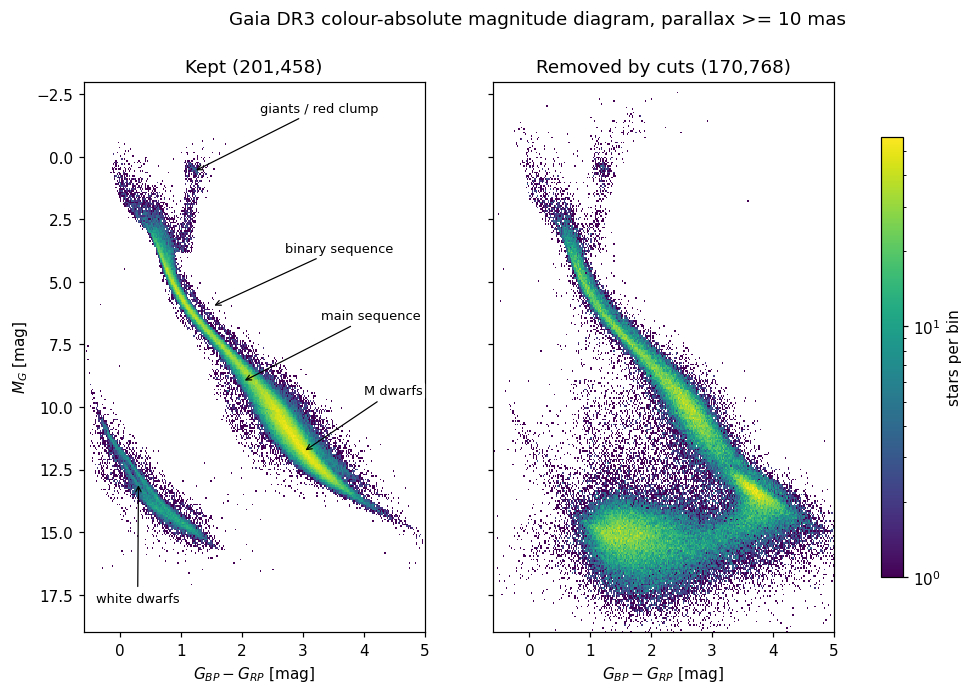

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharex=True, sharey=True)
xr, yr = (-0.6, 5.0), (-3.0, 19.0)
for ax, data, title in [(axes[0], clean, f"Kept ({len(clean):,})"),
                        (axes[1], rejected, f"Removed by cuts ({len(rejected):,})")]:
    ok = data["bp_rp"].notna() & data["mg"].notna()
    h = ax.hist2d(data.loc[ok, "bp_rp"], data.loc[ok, "mg"], bins=(280, 330),
                  range=(xr, yr), norm=LogNorm(), cmap="viridis", cmin=1)
    ax.set_title(title)
    ax.set_xlabel(r"$G_{BP} - G_{RP}$ [mag]")
axes[0].set_ylabel(r"$M_G$ [mag]")
axes[0].set_xlim(*xr)
axes[0].set_ylim(yr[1], yr[0])
fig.colorbar(h[3], ax=axes, label="stars per bin", shrink=0.8)

# Approximate positions of the main features (label position, arrow target)
notes = [("main sequence", (3.3, 6.5), (2.0, 9.0)),
         ("binary sequence", (2.7, 3.8), (1.5, 6.0)),
         ("white dwarfs", (-0.4, 17.8), (0.3, 13.0)),
         ("giants / red clump", (2.3, -1.8), (1.2, 0.6)),
         ("M dwarfs", (4.0, 9.5), (3.0, 11.8))]
for text, xytext, xy in notes:
    axes[0].annotate(text, xy=xy, xytext=xytext, fontsize=8.5, color="black",
                     arrowprops=dict(arrowstyle="->", lw=0.8, color="black"),
                     bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, lw=0))
fig.suptitle("Gaia DR3 colour-absolute magnitude diagram, parallax >= 10 mas")
fig.savefig(FIG / "01_hrd_100pc.png")
plt.show()

## 5. Completeness test: does N(<d) grow like d³?

**Hypothesis.** If stars were spread with constant density and the sample were complete, the number of stars within distance d would grow as N(<d) ∝ d³, so N(<d)/d³ would be flat.

**Expectation.** Bright stars stay flat out to 100 pc. Faint stars (white dwarfs, late M dwarfs, brown dwarfs) fall below the line beyond some distance because the `parallax_over_error ≥ 10` cut and Gaia's magnitude limit remove them. Local structures, such as the Hyades cluster at about 47 pc, add bumps. Small-number noise dominates close to the Sun, so the curves start at 15 pc and are normalised to their value in 20 to 30 pc.

This is the astronomical version of a rarefaction curve: the point where the curve drops is the detection limit for that brightness class.

**Note added after the first run.** The table below only flags losses beyond 30 pc, so it stays silent for curves that *rise* with distance. In the first run the bright classes (M_G < 10 and 10 to 13) rose by 20 to 30 %, which means stars are missing nearby, not far away. Section 8.1 tests why.

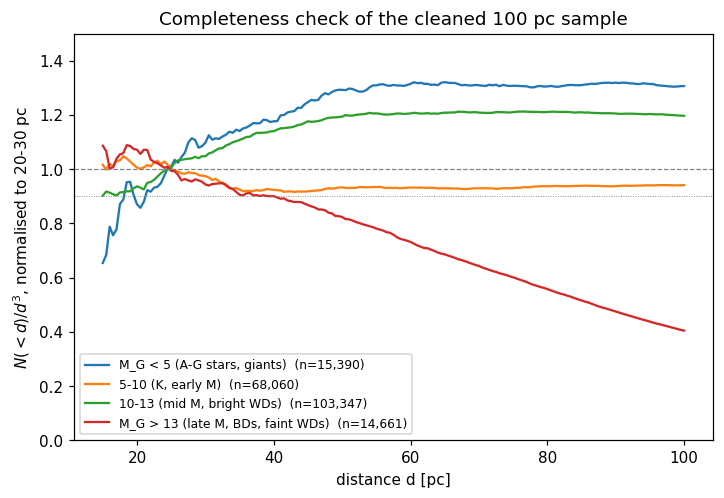

                        M_G class  n stars  first d > 30 pc with ratio < 0.9 [pc]
      M_G < 5 (A-G stars, giants)    15390                                    NaN
                5-10 (K, early M)    68060                                    NaN
        10-13 (mid M, bright WDs)   103347                                    NaN
M_G > 13 (late M, BDs, faint WDs)    14661                                   40.5


In [6]:
bins_mg = [(-5, 5, "M_G < 5 (A-G stars, giants)"), (5, 10, "5-10 (K, early M)"),
           (10, 13, "10-13 (mid M, bright WDs)"), (13, 25, "M_G > 13 (late M, BDs, faint WDs)")]
d_grid = np.linspace(15, 100, 171)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
summary = []
for lo, hi, label in bins_mg:
    d = np.sort(clean.loc[(clean["mg"] >= lo) & (clean["mg"] < hi), "dist_pc"].to_numpy())
    if len(d) < 50:
        continue
    n_cum = np.searchsorted(d, d_grid, side="right")
    ratio = n_cum / d_grid**3
    ref = (d_grid >= 20) & (d_grid <= 30)
    norm = ratio / np.nanmean(ratio[ref])
    ax.plot(d_grid, norm, label=f"{label}  (n={len(d):,})")
    below = d_grid[(d_grid > 30) & (norm < 0.9)]
    summary.append((label, len(d), below[0] if len(below) else np.nan))

ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.axhline(0.9, color="grey", lw=0.6, ls=":")
ax.set_xlabel("distance d [pc]")
ax.set_ylabel(r"$N(<d)/d^3$, normalised to 20-30 pc")
ax.set_ylim(0, 1.5)
ax.legend(fontsize=8)
ax.set_title("Completeness check of the cleaned 100 pc sample")
fig.savefig(FIG / "01_completeness.png")
plt.show()

comp = pd.DataFrame(summary, columns=["M_G class", "n stars", "first d > 30 pc with ratio < 0.9 [pc]"])
print(comp.to_string(index=False))

## 6. Sky map in Galactic coordinates

Within 100 pc the stars are spread almost evenly over the sky, because the Milky Way disc is several hundred parsec thick. The map is centred on the Galactic anticentre (l = 180°) and longitude increases to the left (astronomical convention). Look for:
- an overdensity near l ≈ 180°, b ≈ −22°: the **Hyades** cluster at about 47 pc;
- stripes or patches in the faint classes: imprints of Gaia's scanning law (how often each sky region was observed), a selection effect, not real structure.

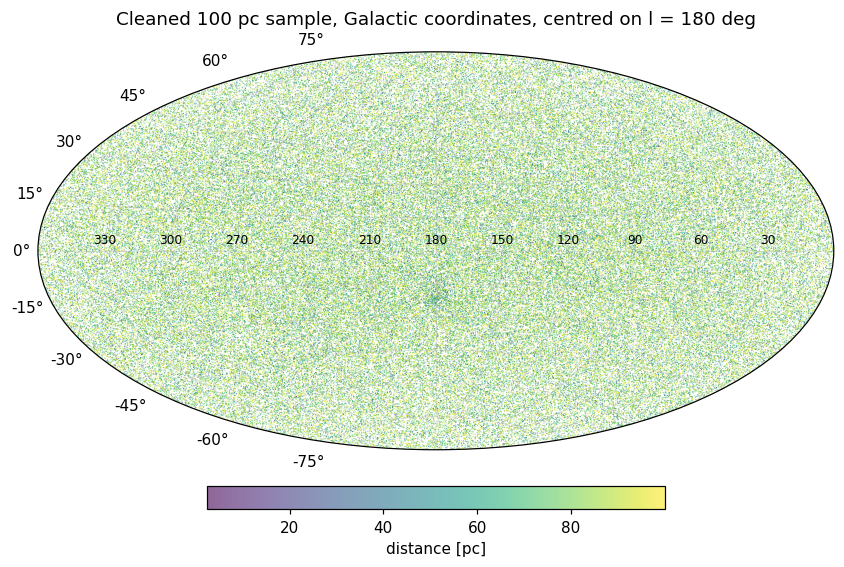

In [7]:
# Map centred on the Galactic anticentre (l = 180 deg) so that the Hyades and the
# Pleiades (both in Taurus) are not split at the map edge.
delta = (clean["l"].to_numpy() % 360) - 180          # 0 at l = 180 deg
x = np.radians(-delta)                                # l increases to the left
fig = plt.figure(figsize=(10, 5.4))
ax = fig.add_subplot(projection="aitoff")
sc = ax.scatter(x, np.radians(clean["b"]), c=clean["dist_pc"], s=0.5,
                alpha=0.6, cmap="viridis", rasterized=True, linewidths=0)
ticks = np.array([-150, -120, -90, -60, -30, 0, 30, 60, 90, 120, 150])
ax.set_xticks(np.radians(ticks))
ax.set_xticklabels([f"{(180 - t) % 360:d}" for t in ticks], fontsize=8)
ax.grid(True, lw=0.4, alpha=0.5)
ax.set_title("Cleaned 100 pc sample, Galactic coordinates, centred on l = 180 deg", pad=18)
fig.colorbar(sc, ax=ax, orientation="horizontal", fraction=0.05, pad=0.08, label="distance [pc]")
fig.savefig(FIG / "01_sky_galactic.png")
plt.show()

## 7. Vector point diagram (proper motions)

Field stars form a broad cloud around the origin. Members of a cluster move together and appear as a tight clump. Nearby clusters have large proper motions because the same space velocity looks bigger on the sky when the cluster is close. Notebook 2 will find such clumps objectively with HDBSCAN; here we only locate the densest clump away from the field centre as a teaser.

**Note added after the first run.** The clump found near (47, -45) mas/yr is *not* a cluster. Its median distance (83 pc) equals the typical distance of the whole sample, and the peak bin holds only 32 stars. The Hyades are too close and too extended on the sky for a compact clump: their proper motions vary by tens of mas/yr across the cluster (projection effect). A 2 mas/yr grid cannot see that. Section 8.3 looks for the Hyades with a search window that respects this.

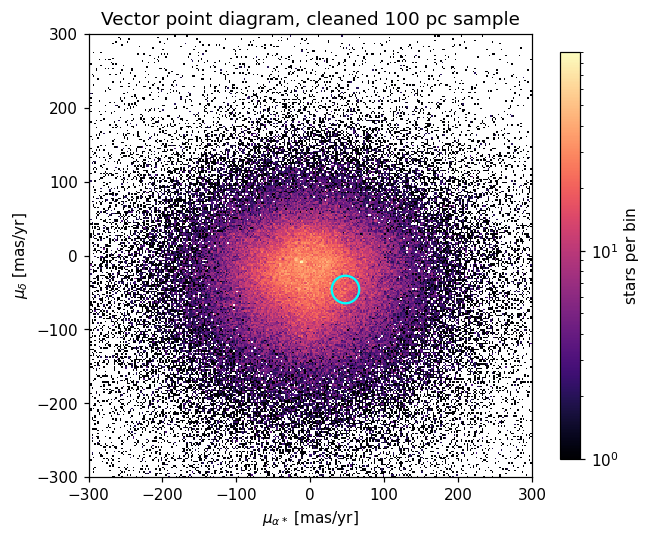

Densest off-centre clump near pmra = 47, pmdec = -45 mas/yr (32 stars in the peak bin)
Stars within 6 mas/yr of the peak: 523, median distance 83.2 pc, median l = 155.6 deg, b = -11.9 deg


In [8]:
lim = 300
fig, ax = plt.subplots(figsize=(6.5, 6))
h = ax.hist2d(clean["pmra"], clean["pmdec"], bins=300, range=((-lim, lim), (-lim, lim)),
              norm=LogNorm(), cmap="magma", cmin=1)
ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/yr]")
ax.set_ylabel(r"$\mu_\delta$ [mas/yr]")
ax.set_aspect("equal")
ax.set_title("Vector point diagram, cleaned 100 pc sample")
fig.colorbar(h[3], ax=ax, shrink=0.8, label="stars per bin")

# Densest bin outside the central field cloud (|mu| > 60 mas/yr)
H, xe, ye = np.histogram2d(clean["pmra"], clean["pmdec"], bins=300, range=((-lim, lim), (-lim, lim)))
xc, yc = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
XX, YY = np.meshgrid(xc, yc, indexing="ij")
H_out = np.where(np.hypot(XX, YY) > 60, H, 0)
i, j = np.unravel_index(np.argmax(H_out), H_out.shape)
ax.plot(xc[i], yc[j], "o", mfc="none", mec="cyan", ms=18, mew=1.5)
fig.savefig(FIG / "01_vpd.png")
plt.show()

sel = (np.hypot(clean["pmra"] - xc[i], clean["pmdec"] - yc[j]) < 6)
print(f"Densest off-centre clump near pmra = {xc[i]:.0f}, pmdec = {yc[j]:.0f} mas/yr "
      f"({int(H[i, j])} stars in the peak bin)")
print(f"Stars within 6 mas/yr of the peak: {sel.sum()}, "
      f"median distance {clean.loc[sel, 'dist_pc'].median():.1f} pc, "
      f"median l = {clean.loc[sel, 'l'].median():.1f} deg, b = {clean.loc[sel, 'b'].median():.1f} deg")

## 8. Three follow-up checks

The first run raised three questions. Each check below states what is done, why, what it costs, and what I **expect** before you run it. If a result contradicts the expectation, that is informative, not a failure.

| Check | Question | Expectation |
|---|---|---|
| 8.1 | Why do bright classes *rise* in the completeness plot? Is the RUWE cut depleting the nearby volume? | Curves flatten when the RUWE cut is loosened; the fraction of stars failing RUWE falls with distance |
| 8.2 | What is the blob between the white dwarfs and the main sequence among the removed stars? | Spurious sources, concentrated towards the Galactic plane and the inner Galaxy |
| 8.3 | Are the Hyades visible when we search where the literature says they are? | A clump of a few hundred stars at about 47 pc with a narrow main sequence |

Variables you may change are written in capitals at the top of each code cell.

### 8.1 Does the RUWE cut deplete the nearby volume?

**What.** Repeat the completeness curve of section 5 for several RUWE thresholds, and measure the fraction of stars that fail RUWE in different distance and magnitude ranges.

**Why.** RUWE measures how badly a single-star motion fits the data. For a binary, the photocentre wobbles on a small orbit. The angular size of that wobble in mas equals orbit size in AU times parallax in mas, so the same binary produces a larger wobble when it is nearer. Nearby binaries are therefore detected (and removed) more often than distant ones. This would deplete the reference zone (20 to 30 pc) relative to larger distances, and all curves would look too high beyond it.

**Competing explanation.** Very bright stars (G below about 6) also have worse astrometry and higher RUWE. Because nearby stars are brighter on the sky, magnitude and distance are tangled. The second table separates them: at fixed G, does the failure rate still change with distance?

**Cost of loosening RUWE.** More binaries and some bad solutions stay in the sample. There is no free setting, only a trade between purity and completeness (analogue: choosing a missing-rate or HWE threshold in genotype QC).

**Expectation.** (1) Curves for the bright classes get flatter as the RUWE cut is loosened. (2) The failure rate falls with distance. (3) At fixed G, nearer stars still fail more often. If (3) is false, the magnitude explanation is enough.

**Exercise.** Change `RUWE_VALUES` (for example add 1.1 or 3.0) and watch which class reacts most.

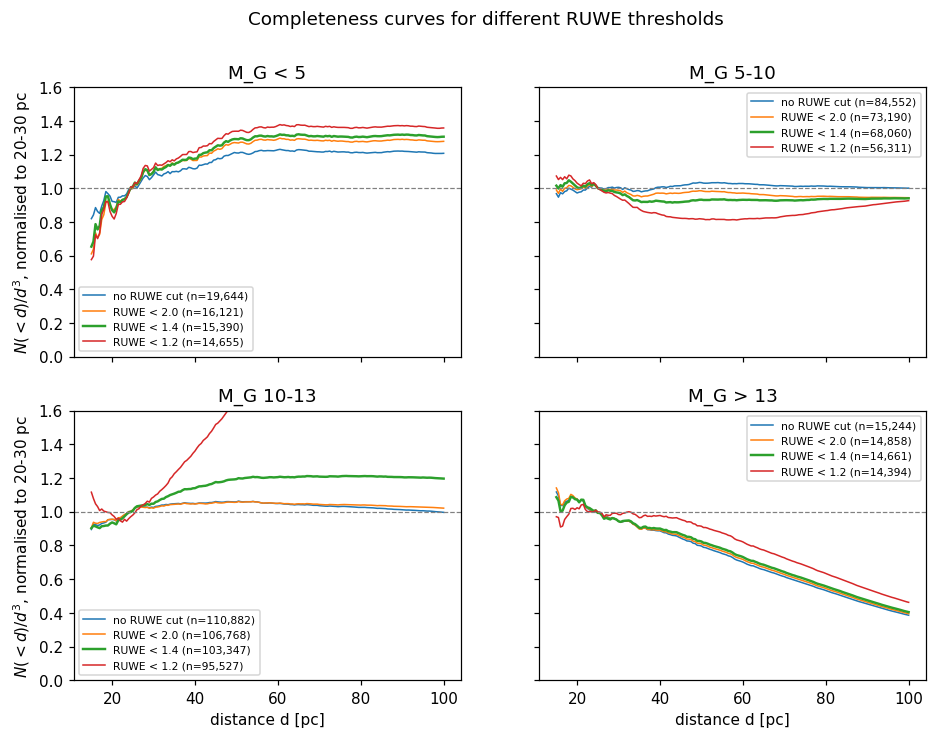

    class      sample      n  ratio at 50 pc  ratio at 90 pc
  M_G < 5 no RUWE cut  19644            1.21            1.22
  M_G < 5  RUWE < 2.0  16121            1.27            1.29
  M_G < 5  RUWE < 1.4  15390            1.29            1.32
  M_G < 5  RUWE < 1.2  14655            1.34            1.37
 M_G 5-10 no RUWE cut  84552            1.03            1.00
 M_G 5-10  RUWE < 2.0  73190            0.99            0.95
 M_G 5-10  RUWE < 1.4  68060            0.93            0.94
 M_G 5-10  RUWE < 1.2  56311            0.82            0.90
M_G 10-13 no RUWE cut 110882            1.06            1.01
M_G 10-13  RUWE < 2.0 106768            1.06            1.03
M_G 10-13  RUWE < 1.4 103347            1.19            1.21
M_G 10-13  RUWE < 1.2  95527            1.66            2.14
 M_G > 13 no RUWE cut  15244            0.80            0.45
 M_G > 13  RUWE < 2.0  14858            0.81            0.46
 M_G > 13  RUWE < 1.4  14661            0.82            0.47
 M_G > 13  RUWE < 1.2  1

In [9]:
RUWE_VALUES = [None, 2.0, 1.4, 1.2]     # None = no RUWE cut at all. Exercise: change these.

# Stars passing the three photometric cuts, whatever their RUWE
other = pd.Series(True, index=df.index)
for name, mask in cuts[1:]:
    other &= mask.fillna(False).astype(bool)

d_grid = np.linspace(15, 100, 171)
classes = [(-5, 5, "M_G < 5"), (5, 10, "M_G 5-10"), (10, 13, "M_G 10-13"), (13, 25, "M_G > 13")]


def completeness_curve(dist, d_grid, ref=(20, 30)):
    d = np.sort(np.asarray(dist))
    ratio = np.searchsorted(d, d_grid, side="right") / d_grid**3
    r = (d_grid >= ref[0]) & (d_grid <= ref[1])
    return ratio / np.nanmean(ratio[r])


fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
rows = []
for ax, (lo, hi, label) in zip(axes.ravel(), classes):
    for t in RUWE_VALUES:
        sel = other if t is None else other & (df["ruwe"] < t)
        sel = sel & (df["mg"] >= lo) & (df["mg"] < hi)
        if sel.sum() < 50:
            continue
        curve = completeness_curve(df.loc[sel, "dist_pc"], d_grid)
        name = "no RUWE cut" if t is None else f"RUWE < {t}"
        ax.plot(d_grid, curve, lw=1.6 if t == 1.4 else 1.0, label=f"{name} (n={sel.sum():,})")
        rows.append((label, name, int(sel.sum()),
                     np.interp(50, d_grid, curve), np.interp(90, d_grid, curve)))
    ax.axhline(1, color="grey", lw=0.8, ls="--")
    ax.set_title(label)
    ax.set_ylim(0, 1.6)
    ax.legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel("distance d [pc]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$N(<d)/d^3$, normalised to 20-30 pc")
fig.suptitle("Completeness curves for different RUWE thresholds")
fig.savefig(FIG / "01_completeness_ruwe.png")
plt.show()

tab_a = pd.DataFrame(rows, columns=["class", "sample", "n", "ratio at 50 pc", "ratio at 90 pc"])
print(tab_a.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# (2) Fraction failing RUWE >= 1.4 by distance bin, among stars passing the other cuts
print("\nFraction of stars with RUWE >= 1.4 [%] by distance bin (other cuts applied)")
dbins = [15, 30, 50, 75, 100]
tab_b = []
for lo, hi, label in classes:
    row = {"class": label}
    for d0, d1 in zip(dbins[:-1], dbins[1:]):
        m = other & (df["mg"] >= lo) & (df["mg"] < hi) & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1)
        row[f"{d0}-{d1} pc"] = 100 * (df.loc[m, "ruwe"] >= 1.4).mean() if m.sum() >= 30 else np.nan
    tab_b.append(row)
print(pd.DataFrame(tab_b).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# (3) Same question at fixed apparent magnitude G: near versus far
print("\nFraction with RUWE >= 1.4 [%] at fixed G, near versus far (other cuts applied)")
gbins = [(0, 6), (6, 9), (9, 12), (12, 15), (15, 21)]
tab_c = []
for g0, g1 in gbins:
    row = {"G range": f"{g0}-{g1}"}
    for name, d0, d1 in [("15-40 pc", 15, 40), ("40-100 pc", 40, 100)]:
        m = (other & (df["phot_g_mean_mag"] >= g0) & (df["phot_g_mean_mag"] < g1)
             & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1))
        row[name] = 100 * (df.loc[m, "ruwe"] >= 1.4).mean() if m.sum() >= 30 else np.nan
        row[f"n {name}"] = int(m.sum())
    tab_c.append(row)
print(pd.DataFrame(tab_c).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

**How to read the three outputs.**
- *Curves and first table:* a class whose ratio at 50 and 90 pc moves towards 1.0 when the RUWE cut is loosened was being distorted by it. Compare the n column: the price of loosening is more stars of lower quality.
- *Second table:* a falling failure rate with distance supports the geometric argument (binary wobble scales with parallax).
- *Third table:* if the near column is clearly higher than the far column within the same G range, the effect is truly about distance. If both columns match, the earlier trend was only a magnitude effect. Rows with very few stars are blank.

**Record your reading here:** Without a RUWE cut, M_G 5-13 is complete to 100 pc. The RUWE cut depletes nearby mid-M dwarfs (failure rate 21 % at 15-30 pc vs 5 % at 75-100 pc), most likely because nearby stars are measured more precisely, so binaries are detected more often (test power). The rise of the M_G < 5 curve persists without a RUWE cut and is attributed to Gaia's bright limit, not to RUWE. RUWE < 1.2 is too strict for this sample. The fixed-G table is confounded by stellar type.

### 8.2 What are the removed stars below the white dwarfs?

**What.** Select removed sources in a box of the HRD that is almost empty of real stars, and look at where they sit on the sky.

**Why.** In the right panel of the HRD (section 4) there is a large blob at M_G of about 14 to 18, between the white dwarf sequence and the main sequence. Real stars are rare there. The usual cause is a wrong parallax. If a faint, distant star in a crowded field is blended with a neighbour, its parallax can come out several times too large. The absolute magnitude uses 5 log10(parallax), so a parallax that is 5 times too large makes the star appear about 3.5 mag too faint, which moves it below the main sequence. Crowded fields are the Galactic plane and the inner Galaxy.

**Cost / caveat.** The box is a judgement call. Faint cool white dwarfs may enter its upper edge. The box is chosen low enough (M_G > 16.5) to avoid most of them.

**Analogue.** Like reads that map to the wrong place in repetitive genome regions: an artefact that concentrates where the reference is ambiguous, not where the biology is.

**Expectation.** The box sources sit preferentially at low Galactic latitude and towards the inner Galaxy, in contrast to real nearby stars, which are spread evenly. A test: the fraction of sources at |b| < 15 deg should be clearly above the uniform value of 25.9 %, and the fraction at |l| < 60 deg clearly above 33.3 %.

**Exercise.** Change `BOX` (for example to bp_rp 1.0 to 2.5 and mg 15 to 17) and see how the numbers move. Then compare the last printout of the code cell: if the sources are blends, most of them should fail the RUWE cut or the C* cut.

Sources in the box: 6,768, of which kept by all cuts: 3


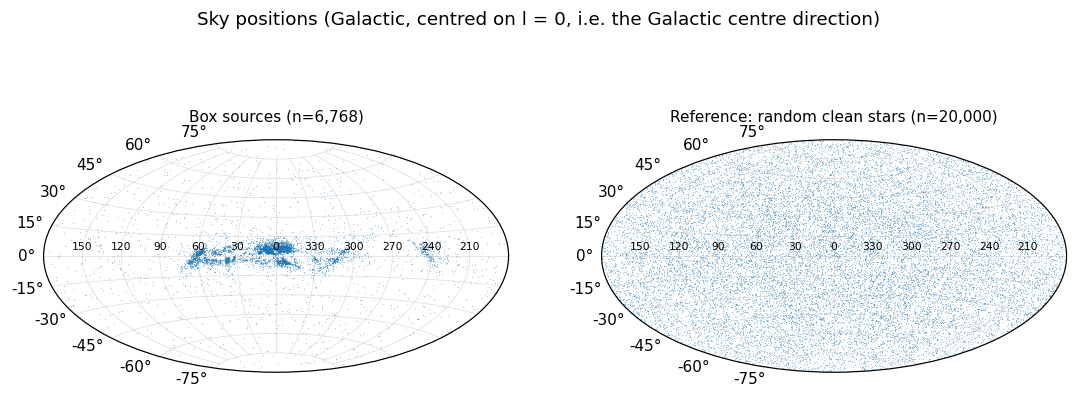

|b| < 15 deg                   box:  86.5 %   clean reference:  26.2 %   uniform sky:  25.9 %
|l| < 60 deg (inner Galaxy)    box:  76.5 %   clean reference:  34.2 %   uniform sky:  33.3 %

Share of box sources that FAIL each cut (a source can fail several):
  RUWE < 1.4                    58.4 %
  G flux S/N > 50               19.4 %
  BP and RP flux S/N > 20       96.2 %
  |C*| < 3 sigma                89.9 %
  any cut                      100.0 %


In [12]:
BOX = dict(bp_rp=(0.5, 3.5), mg=(16.5, 19.0))     # region of the HRD with almost no real stars. Exercise: change this.

in_box = (df["bp_rp"].between(*BOX["bp_rp"]) & df["mg"].between(*BOX["mg"]))
box_src = df[in_box]
ref_src = clean.sample(min(20000, len(clean)), random_state=0)
print(f"Sources in the box: {in_box.sum():,}, of which kept by all cuts: {int(keep[in_box].sum()):,}")


def to_aitoff(l_deg):
    # centred on l = 0, longitude increasing to the left
    l = np.asarray(l_deg) % 360
    return np.radians(-np.where(l > 180, l - 360, l))


fig = plt.figure(figsize=(12, 4.6))
for k, (data, title) in enumerate([(box_src, f"Box sources (n={len(box_src):,})"),
                                   (ref_src, f"Reference: random clean stars (n={len(ref_src):,})")], start=1):
    ax = fig.add_subplot(1, 2, k, projection="aitoff")
    ax.scatter(to_aitoff(data["l"]), np.radians(data["b"]), s=0.6, alpha=0.4, rasterized=True, linewidths=0)
    ticks = np.arange(-150, 151, 30)
    ax.set_xticks(np.radians(ticks))
    ax.set_xticklabels([f"{(-t) % 360}" for t in ticks], fontsize=7)   # label = true l (l increases to the left)
    ax.grid(True, lw=0.4, alpha=0.5)
    ax.set_title(title, fontsize=10, pad=12)
fig.suptitle("Sky positions (Galactic, centred on l = 0, i.e. the Galactic centre direction)")
fig.savefig(FIG / "01_sky_spurious.png")
plt.show()


def share(data, mask_fn):
    return 100 * mask_fn(data).mean()


lon = lambda d: (d["l"] % 360).between(60, 300)          # outside the inner-Galaxy sector
tests = [("|b| < 15 deg", lambda d: d["b"].abs() < 15, 25.9),
         ("|l| < 60 deg (inner Galaxy)", lambda d: ~lon(d), 33.3)]
for name, fn, uniform in tests:
    print(f"{name:30s} box: {share(box_src, fn):5.1f} %   clean reference: {share(ref_src, fn):5.1f} %   uniform sky: {uniform:5.1f} %")

print("\nShare of box sources that FAIL each cut (a source can fail several):")
for name, mask in cuts:
    fail = ~mask.fillna(False).astype(bool)
    print(f"  {name:28s} {100 * fail[in_box].mean():5.1f} %")
print(f"  {'any cut':28s} {100 * (~keep[in_box]).mean():5.1f} %")

**How to read it.** The two numbers per row are the test. A box share well above the uniform value, and a reference close to it, means the box sources concentrate where the sky is crowded: they are mostly measurement artefacts. The last list shows which cut catches them. If RUWE catches most, that is the main safeguard against this contamination, and loosening RUWE (8.1) lets some of them back in. That is the purity-versus-completeness trade-off in one picture.

**Record your reading here:** The box sources concentrate towards the Galactic plane (86.5 % at |b| < 15 deg vs 26 % for clean stars) and the inner Galaxy (76.5 % vs 34 %), so they are mostly spurious solutions from blending in crowded fields, despite parallax_over_error >= 10. All are removed. The colour cuts catch them more efficiently than RUWE (BP/RP S/N 96 %, C* 90 %, RUWE 58 %), so RUWE could be loosened without readmitting this contamination as long as the colour cuts stay.

### 8.3 The Hyades: a confirmation test, not a discovery

**What.** Cut out a window on the sky and in distance around the known position of the Hyades, then ask whether the proper motions pile up near the literature value. The numbers below are approximate literature values (Gaia DR2/DR3 cluster papers listed in `../literature.md`). Check them there before you cite them.

**Why this works where section 7 did not.** All Hyades members share one space velocity, but because the cluster is close and large on the sky, perspective changes the proper motion with position (up to tens of mas/yr). A tiny 2 mas/yr bin cannot hold that spread. A circle of 25 mas/yr around the mean does, and restricting the sky position and distance first removes most field stars. This is the same idea as using a window before a statistical test: define the region from prior knowledge, then ask whether there is an excess.

**Cost.** It is a *confirmation* using prior knowledge, not a discovery. HDBSCAN in notebook 2 does the discovery without being told where to look. The excess estimate below is rough, because the field density is not uniform in proper-motion space.

**Estimating the field contamination.** Count the stars in a ring around the circle (area 4.2 times larger) and divide by 4.2. The difference between the stars inside and this expected background is the excess attributed to the cluster.

**Expectation (my guess, not a measured value).** A clear excess of a few hundred stars, median distance close to 47 pc with a scatter of a few pc, a median proper motion close to the literature value, and a narrower main sequence than the field.

**Exercise.** Make `HY_RADIUS_DEG` smaller (10) or larger (40) and change `PM_RADIUS`. See how the excess and the distance scatter react. A real cluster is robust against reasonable changes; a chance clump is not.

Stars in sky/distance window:          2,053
Inside the proper-motion circle:       285
Expected field stars (ring estimate):  54
Excess attributed to the cluster:      231  (81 % of the circle)
Candidates: median distance 47.4 pc, robust scatter 3.1 pc
Candidates: median pmra = 103.9, pmdec = -27.2 mas/yr (literature guess (101.0, -28.0))


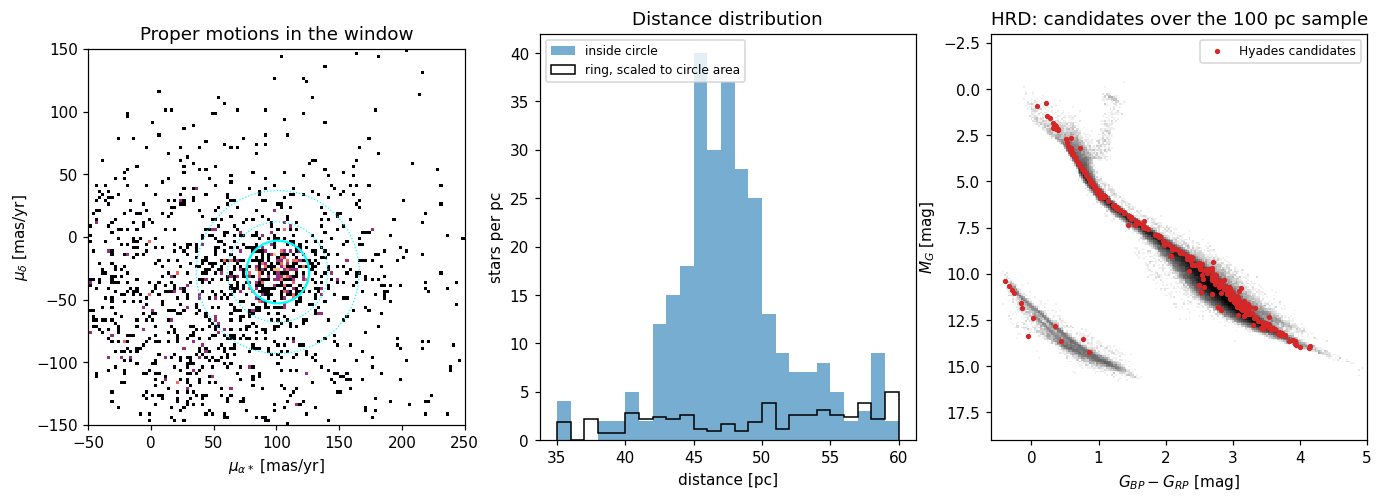

In [11]:
HY_L, HY_B = 180.0, -22.4          # approximate Hyades centre, Galactic degrees
HY_PM = (101.0, -28.0)             # approximate cluster proper motion, mas/yr
HY_RADIUS_DEG = 25.0               # sky window radius. Exercise: change.
HY_DIST = (35.0, 60.0)             # distance window [pc]
PM_RADIUS = 25.0                   # circle in proper-motion space [mas/yr]. Exercise: change.


def angsep_deg(l1, b1, l2, b2):
    l1, b1, l2, b2 = map(np.radians, (l1, b1, l2, b2))
    c = np.sin(b1) * np.sin(b2) + np.cos(b1) * np.cos(b2) * np.cos(l1 - l2)
    return np.degrees(np.arccos(np.clip(c, -1, 1)))


sep = angsep_deg(clean["l"].to_numpy(), clean["b"].to_numpy(), HY_L, HY_B)
win = clean[(sep < HY_RADIUS_DEG) & clean["dist_pc"].between(*HY_DIST)].copy()
win["dpm"] = np.hypot(win["pmra"] - HY_PM[0], win["pmdec"] - HY_PM[1])

cand = win[win["dpm"] < PM_RADIUS]
ring_lo, ring_hi = 1.6 * PM_RADIUS, 2.6 * PM_RADIUS
ring = win[(win["dpm"] >= ring_lo) & (win["dpm"] < ring_hi)]
area_factor = (ring_hi**2 - ring_lo**2) / PM_RADIUS**2
bg = len(ring) / area_factor
excess = len(cand) - bg

mad = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
print(f"Stars in sky/distance window:          {len(win):,}")
print(f"Inside the proper-motion circle:       {len(cand):,}")
print(f"Expected field stars (ring estimate):  {bg:.0f}")
print(f"Excess attributed to the cluster:      {excess:.0f}  ({excess / max(len(cand), 1) * 100:.0f} % of the circle)")
print(f"Candidates: median distance {cand['dist_pc'].median():.1f} pc, robust scatter {mad(cand['dist_pc']):.1f} pc")
print(f"Candidates: median pmra = {cand['pmra'].median():.1f}, pmdec = {cand['pmdec'].median():.1f} mas/yr "
      f"(literature guess {HY_PM})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
ax = axes[0]
h = ax.hist2d(win["pmra"], win["pmdec"], bins=120, range=((-50, 250), (-150, 150)), norm=LogNorm(), cmap="magma", cmin=1)
ax.add_patch(plt.Circle(HY_PM, PM_RADIUS, fill=False, ec="cyan", lw=1.5))
ax.add_patch(plt.Circle(HY_PM, ring_lo, fill=False, ec="cyan", lw=0.8, ls=":"))
ax.add_patch(plt.Circle(HY_PM, ring_hi, fill=False, ec="cyan", lw=0.8, ls=":"))
ax.set_aspect("equal")
ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/yr]"); ax.set_ylabel(r"$\mu_\delta$ [mas/yr]")
ax.set_title("Proper motions in the window")

ax = axes[1]
bins = np.arange(HY_DIST[0], HY_DIST[1] + 1, 1.0)
ax.hist(cand["dist_pc"], bins=bins, histtype="stepfilled", alpha=0.6, label="inside circle")
ax.hist(ring["dist_pc"], bins=bins, histtype="step", weights=np.full(len(ring), 1 / area_factor),
        color="k", label="ring, scaled to circle area")
ax.set_xlabel("distance [pc]"); ax.set_ylabel("stars per pc")
ax.set_title("Distance distribution"); ax.legend(fontsize=8, loc="upper left")

ax = axes[2]
ok = clean["bp_rp"].notna() & clean["mg"].notna()
ax.hist2d(clean.loc[ok, "bp_rp"], clean.loc[ok, "mg"], bins=(200, 240), range=((-0.6, 5), (-3, 19)),
          norm=LogNorm(), cmap="Greys", cmin=1)
ax.scatter(cand["bp_rp"], cand["mg"], s=6, color="tab:red", label="Hyades candidates")
ax.set_ylim(19, -3)
ax.set_xlabel(r"$G_{BP} - G_{RP}$ [mag]"); ax.set_ylabel(r"$M_G$ [mag]")
ax.set_title("HRD: candidates over the 100 pc sample"); ax.legend(fontsize=8)
fig.savefig(FIG / "01_hyades_check.png")
plt.show()

**How to read it.**
- *Left:* a bright concentration inside the solid circle on top of a smooth field cloud means a cluster. The dotted circles bound the ring used for the field estimate.
- *Middle:* a real cluster gives a peak in distance. The black outline is what field stars would give in the same circle area. A peak of the red histogram above the black one at about 47 pc is the cluster.
- *Right:* cluster members of one age and composition fall on a thin sequence, much narrower than the grey field. Expect a few scattered red points off the sequence: contamination, binaries and white dwarfs.

**Record your reading here:** Clear detection: 285 stars in the proper-motion circle versus about 54 expected from the field, an excess of about 230 (roughly 80 % purity). Median distance 47.4 pc, robust scatter 3.1 pc, which reflects the real depth of the cluster, not parallax errors. Proper motions spread by about +-20 mas/yr because of projection, which explains why section 7 missed the cluster. The candidates form a much narrower main sequence than the field, with a few hot white dwarfs at the bright end of the white dwarf sequence. Giants (too bright for Gaia), many binaries (RUWE cut) and the faintest members (BP cut) are missing.

## 9. Summary and next steps

Results of the first run (Gaia DR3, data from AIP Potsdam, 2026-11-15):
- **Sources:** 372,226 downloaded (parallax >= 10 mas, parallax_over_error >= 10), 201,458 kept after the cuts (RUWE 28.4 %, G S/N 0.9 %, BP/RP S/N 20.5 %, C* 4.1 % removed in sequence).
- **HRD:** main sequence, binary sequence, giants with red clump and the white dwarf sequence are visible. The blob between white dwarfs and main sequence among the removed sources is spurious.
- **Completeness:** only the faintest class (M_G > 13) loses stars with distance (below 90 % beyond 40.5 pc, caused by the BP S/N cut). Without a RUWE cut, M_G 5-13 is complete to 100 pc.
- **8.1:** RUWE removes nearby mid-M dwarfs preferentially (test power). The rise of the bright class is a Gaia bright-limit effect. RUWE < 1.2 is too strict.
- **8.2:** box sources are blends in crowded fields (86.5 % at |b| < 15 deg). Colour cuts catch them (BP/RP 96 %, C* 90 %), RUWE only 58 %.
- **8.3:** Hyades recovered: excess of about 230 stars, 47.4 pc, narrow main sequence. The off-centre clump of section 7 was the field.

**Decisions for notebook 2:** no RUWE cut for the membership search (flag high-RUWE stars as probable binaries instead), keep the colour cuts for HRDs, validate HDBSCAN members against Hunt & Reffert 2023.

**Next (notebook 2):** query a cone around the Pleiades (server-side, out to beyond 100 pc), run HDBSCAN on proper motions and parallax, and compare the members with Hunt & Reffert 2023 and Lodieu et al. 2019.